# Verkehrsprognose mit Azure AutoML Endpoint

Dieses Notebook ruft den bereitgestellten Azure-ML-Endpoint (LightGBM) per REST-API auf und prognostiziert das stündliche Verkehrsaufkommen auf der Interstate 94 in Minneapolis.

**Ablauf:**
1. Historische Daten laden
2. Endpoint konfigurieren
3. Payload erstellen und Prognose abrufen
4. Ergebnisse visualisieren: Einzelstunde, 7-Tage-Historie, 24-Stunden-Dashboard


In [ ]:
# Benötigte Bibliotheken importieren
import urllib.request
import json
import pandas as pd
import matplotlib.pyplot as plt
import plotly.graph_objects as go
import os
from dotenv import load_dotenv, find_dotenv

StatementMeta(28873402-26de-47db-96d5-5cb1e7e0f757, 1, 7, Finished, Available, Finished, False)

## Daten laden

Der Datensatz wird geladen und auf doppelte Zeitstempel geprüft. Diese hatten im ersten AutoML-Lauf zu einem Fehler geführt.

In [3]:
# # CSV mit historischen Daten laden
df_hist = pd.read_csv("Users/anna.mueller1/Metro_Interstate_Traffic_Volume.csv")

# # Datumsspalte in Datumsformat umwandeln
df_hist["date_time"] = pd.to_datetime(df_hist["date_time"])

#Testmässig, weil ich ja doppelte Einträge hatte
print("Datensätze:", len(df_hist))
print("Zeitraum:", df_hist["date_time"].min(), "bis", df_hist["date_time"].max())
print("Doppelte Zeitstempel:", df_hist["date_time"].duplicated().sum())

df_hist.info()

StatementMeta(28873402-26de-47db-96d5-5cb1e7e0f757, 1, 8, Finished, Available, Finished, False)

Datensätze: 48204
Zeitraum: 2012-10-02 09:00:00 bis 2018-09-30 23:00:00
Doppelte Zeitstempel: 7629
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48204 entries, 0 to 48203
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   holiday              61 non-null     object        
 1   temp                 48204 non-null  float64       
 2   rain_1h              48204 non-null  float64       
 3   snow_1h              48204 non-null  float64       
 4   clouds_all           48204 non-null  int64         
 5   weather_main         48204 non-null  object        
 6   weather_description  48204 non-null  object        
 7   date_time            48204 non-null  datetime64[ns]
 8   traffic_volume       48204 non-null  int64         
dtypes: datetime64[ns](1), float64(3), int64(2), object(3)
memory usage: 3.3+ MB


## Schritt 1: Endpoint-URL und API-Key

URL und API-Key werden aus einer lokalen `.env`-Datei geladen und sind nicht im Repository enthalten. Die benötigten Variablen sind in `.env.example` aufgeführt.

In [ ]:
# Endpoint-URL und API-Key aus der .env-Datei laden
load_dotenv(find_dotenv(usecwd=True))

url = os.getenv("AZURE_ENDPOINT_URL")
api_key = os.getenv("AZURE_API_KEY")

if not url or not api_key:
    raise ValueError("AZURE_ENDPOINT_URL oder AZURE_API_KEY fehlt in der .env-Datei.")

headers = {
    "Content-Type": "application/json",
    "Authorization": "Bearer " + api_key
}

StatementMeta(28873402-26de-47db-96d5-5cb1e7e0f757, 1, 9, Finished, Available, Finished, False)

## Schritt 2: Payload erstellen

Als Eingabe dient die letzte historische Stunde. Die Zielvariable `traffic_volume` wird entfernt, der Zeitstempel um eine Stunde verschoben und das Wetter leicht angepasst (+2 °C, leichter Regen, 70 % Bewölkung). So entsteht ein synthetischer Zukunftszeitpunkt.

In [5]:
# Letzte Stunde aus Historie
last_hour = df_hist.tail(1).copy()

# traffic_volume (Target) entfernen
last_hour = last_hour.drop(columns=["traffic_volume"])

# Datum um 1 Stunde nach vorne verschieben
last_hour["date_time"] = last_hour["date_time"] + pd.Timedelta(hours=1)

# Features minimal anpassen
last_hour["temp"] = last_hour["temp"] + 2.0       # 2 Kelvin wärmer (= +2 °C)
last_hour["rain_1h"] = 0.5                        # leichter Regen
last_hour["clouds_all"] = 70                     # 70 % Bewölkung
last_hour["weather_main"] = "Rain"
last_hour["weather_description"] = "light rain"

# Datum in String umwandeln
last_hour["date_time"] = last_hour["date_time"].dt.strftime("%Y-%m-%d %H:%M:%S")

# Payload bauen
data = {
    "input_data": {
        "columns": list(last_hour.columns),
        "index": list(range(len(last_hour))),
        "data": last_hour.values.tolist()
    }
}


StatementMeta(28873402-26de-47db-96d5-5cb1e7e0f757, 1, 10, Finished, Available, Finished, False)

## Schritt 3: Einzelstundenprognose

Die Payload wird als JSON an den Endpoint gesendet. Die Antwort wird in einen DataFrame umgewandelt und als Prognosepunkt dargestellt.

StatementMeta(28873402-26de-47db-96d5-5cb1e7e0f757, 1, 21, Finished, Available, Finished, True)

Antwort des Endpoints: [635.3661432630824]


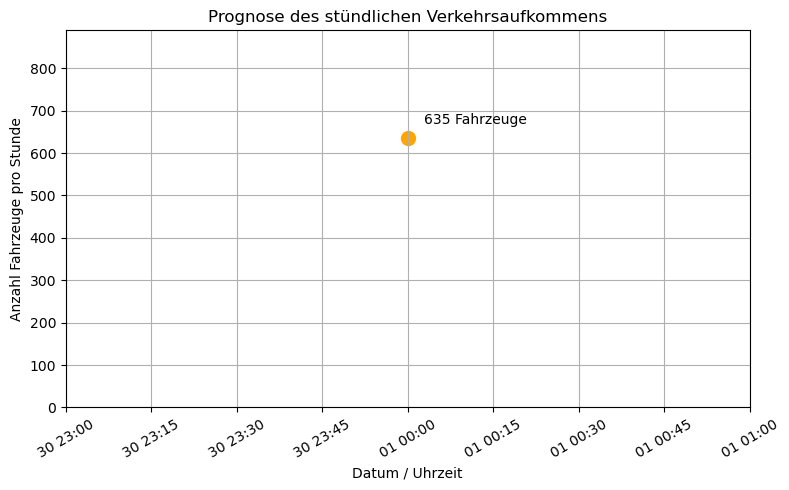

Prognosezeitpunkt: 01.10.2018 00:00
Vorhergesagtes Verkehrsaufkommen: 635 Fahrzeuge/Stunde


In [16]:
# Anfrage an den Endpoint senden
body = json.dumps(data).encode("utf-8")
req = urllib.request.Request(url, body, headers)

response = urllib.request.urlopen(req)
result = response.read()

# Antwort anzeigen
preds = json.loads(result.decode("utf-8"))
print("Antwort des Endpoints:", preds)

# Vorhersage in DataFrame umwandeln
date_col = data["input_data"]["columns"].index("date_time")
dates = [row[date_col] for row in data["input_data"]["data"]]

df = pd.DataFrame({
    "date": pd.to_datetime(dates),
    "forecast": preds
})

# Vorhersage visualisieren
plt.figure(figsize=(8, 5))
plt.scatter(df["date"], df["forecast"], color="orange", s=100)

# Wert direkt beim Punkt anzeigen
for _, row in df.iterrows():
    plt.annotate(
        f'{row["forecast"]:.0f} Fahrzeuge',
        (row["date"], row["forecast"]),
        xytext=(12, 10),
        textcoords="offset points"
    )

plt.title("Prognose des stündlichen Verkehrsaufkommens")
plt.xlabel("Datum / Uhrzeit")
plt.ylabel("Anzahl Fahrzeuge pro Stunde")

# Zeitachse auf die Prognosestunde begrenzen
forecast_time = df["date"].iloc[0]
plt.xlim(
    forecast_time - pd.Timedelta(hours=1),
    forecast_time + pd.Timedelta(hours=1)
)

plt.ylim(0, max(df["forecast"]) * 1.4)
plt.xticks(rotation=30)
plt.grid(True)
plt.tight_layout()
plt.show()

# Prognoseergebnis als Text ausgeben
print(f"Prognosezeitpunkt: {forecast_time:%d.%m.%Y %H:%M}")
print(f"Vorhergesagtes Verkehrsaufkommen: {df['forecast'].iloc[0]:.0f} Fahrzeuge/Stunde")



## Schritt 4: Prognose im Kontext der letzten 7 Tage

Die Prognosestunde wird an die tatsächlichen Werte der letzten sieben Tage angefügt. Doppelte Zeitstempel werden gemittelt. So lässt sich die Prognose mit dem bisherigen Verlauf vergleichen.

StatementMeta(28873402-26de-47db-96d5-5cb1e7e0f757, 1, 19, Finished, Available, Finished, False)

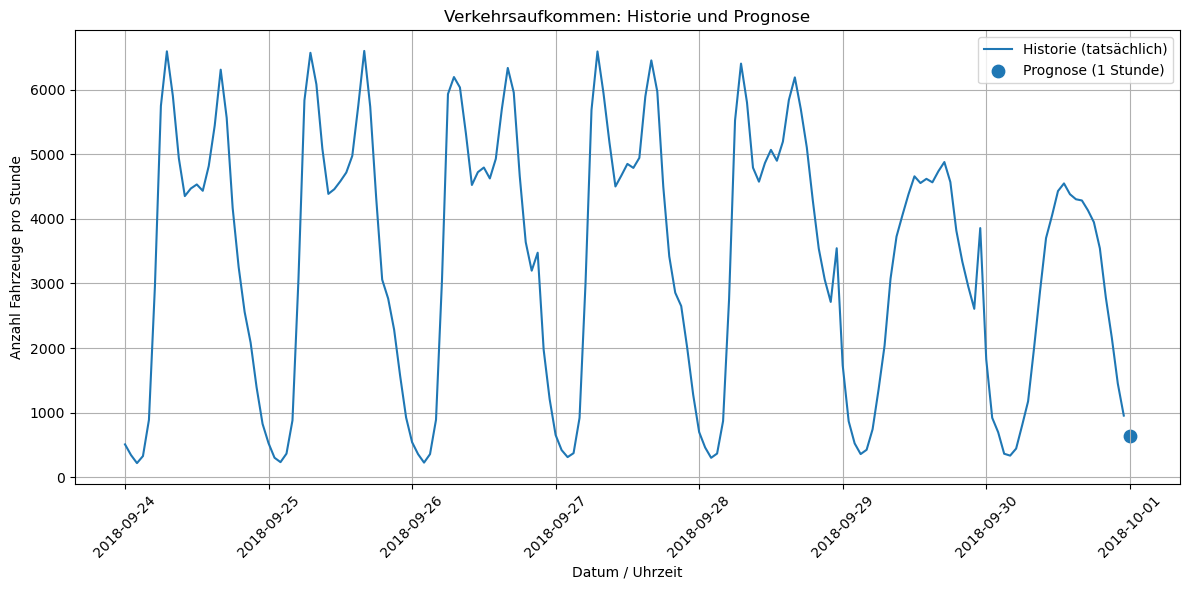

In [14]:
# Historie: letzte 7 Tage vor Beginn der Vorhersage
hist_window = 7

first_forecast_date = df["date"].min()

df_hist_plot = df_hist[
    (df_hist["date_time"] >= first_forecast_date - pd.Timedelta(days=hist_window))
    & (df_hist["date_time"] < first_forecast_date)
].copy()

# Doppelte Zeitstempel zusammenfassen
df_hist_plot = (
    df_hist_plot.groupby("date_time", as_index=False)["traffic_volume"]
    .mean()
)

# Plot
plt.figure(figsize=(12, 6))

plt.plot(
    df_hist_plot["date_time"],
    df_hist_plot["traffic_volume"],
    label="Historie (tatsächlich)"
)

plt.scatter(
    df["date"],
    df["forecast"],
    label="Prognose (1 Stunde)",
    marker="o",
    s=80
)

plt.title("Verkehrsaufkommen: Historie und Prognose")
plt.xlabel("Datum / Uhrzeit")
plt.ylabel("Anzahl Fahrzeuge pro Stunde")
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


### Datenkontrolle

Prüft Zeitstempel, Werte und Datentypen von Historie und Prognose.

In [9]:
print("Historische Daten:")
print(df_hist_plot[["date_time", "traffic_volume"]].tail(10))

print("\nVorhersage:")
print(df[["date", "forecast"]])

print("\nDatentypen:")
print(df_hist_plot[["date_time", "traffic_volume"]].dtypes)
print(df[["date", "forecast"]].dtypes)


StatementMeta(28873402-26de-47db-96d5-5cb1e7e0f757, 0, 14, Finished, Available, Finished, False)

Historische Daten:
              date_time  traffic_volume
158 2018-09-30 14:00:00          4380.0
159 2018-09-30 15:00:00          4302.0
160 2018-09-30 16:00:00          4283.0
161 2018-09-30 17:00:00          4132.0
162 2018-09-30 18:00:00          3947.0
163 2018-09-30 19:00:00          3543.0
164 2018-09-30 20:00:00          2781.0
165 2018-09-30 21:00:00          2159.0
166 2018-09-30 22:00:00          1450.0
167 2018-09-30 23:00:00           954.0

Vorhersage:
        date    forecast
0 2018-10-01  635.366143

Datentypen:
date_time         datetime64[ns]
traffic_volume           float64
dtype: object
date        datetime64[ns]
forecast           float64
dtype: object


## Schritt 5: 24-Stunden-Prognose

Für die nächsten 24 Stunden wird je eine Zeile erzeugt. Die Wetterwerte der letzten Stunde bleiben dabei konstant. Alle Zeilen werden in einer Anfrage an den Endpoint gesendet.

In [10]:

# TEST: Prognose für die nächsten 24 Stunden

# Letzte historische Stunde auswählen
last_row = df_hist.sort_values("date_time").tail(1).copy()

# Zielvariable entfernen
last_row = last_row.drop(columns=["traffic_volume"])

# 24 zukünftige Stunden erstellen
future_rows = []

for i in range(1, 25):
    row = last_row.copy()

    row["date_time"] = (
        row["date_time"] + pd.Timedelta(hours=i)
    )

    future_rows.append(row)

future_df = pd.concat(future_rows, ignore_index=True)

# Datum für Azure formatieren
future_df["date_time"] = future_df["date_time"].dt.strftime(
    "%Y-%m-%d %H:%M:%S"
)

# Payload erstellen
test_payload = {
    "input_data": {
        "columns": list(future_df.columns),
        "index": list(range(len(future_df))),
        "data": future_df.values.tolist()
    }
}

# Endpoint aufrufen
body = json.dumps(test_payload).encode("utf-8")
req = urllib.request.Request(url, body, headers)

try:
    response = urllib.request.urlopen(req)
    result = json.loads(response.read().decode("utf-8"))

    print("Anzahl Vorhersagen:", len(result))

    # Ergebnisse als Tabelle darstellen
    forecast_24h = pd.DataFrame({
        "date_time": pd.to_datetime(future_df["date_time"]),
        "forecast": result
    })

    print(forecast_24h.to_string(index=False))

except urllib.error.HTTPError as error:
    print("Endpoint-Fehler:", error.code)
    print(error.read().decode("utf-8"))


StatementMeta(28873402-26de-47db-96d5-5cb1e7e0f757, 1, 15, Finished, Available, Finished, False)

Anzahl Vorhersagen: 24
          date_time    forecast
2018-10-01 00:00:00  636.247046
2018-10-01 01:00:00  494.082127
2018-10-01 02:00:00  435.103030
2018-10-01 03:00:00  501.534687
2018-10-01 04:00:00  748.465981
2018-10-01 05:00:00 2220.300785
2018-10-01 06:00:00 4248.034748
2018-10-01 07:00:00 4847.615019
2018-10-01 08:00:00 4694.637319
2018-10-01 09:00:00 4587.394873
2018-10-01 10:00:00 4457.107376
2018-10-01 11:00:00 4774.147045
2018-10-01 12:00:00 5061.945316
2018-10-01 13:00:00 5143.718492
2018-10-01 14:00:00 5535.610388
2018-10-01 15:00:00 6111.625611
2018-10-01 16:00:00 6602.698060
2018-10-01 17:00:00 6180.148344
2018-10-01 18:00:00 4639.016608
2018-10-01 19:00:00 3282.747533
2018-10-01 20:00:00 2838.721160
2018-10-01 21:00:00 2563.781533
2018-10-01 22:00:00 2150.758332
2018-10-01 23:00:00 1491.743883


## Schritt 6: Dashboard

Das interaktive Dashboard zeigt die letzten 24 Stunden (blau) und die 24-Stunden-Prognose (orange). Die gestrichelte Linie trennt Historie und Prognose. Mit Zoom, Hover und Legende lassen sich Verkehrsspitzen und ruhigere Phasen schnell erkennen.

In [11]:

# DASHBOARD: 24 Stunden Historie + 24 Stunden Prognose

# Letzten historischen Zeitpunkt bestimmen
last_time = df_hist["date_time"].max()

# Historische Daten der letzten 24 Stunden
history_24h = df_hist[
    (df_hist["date_time"] > last_time - pd.Timedelta(hours=24)) &
    (df_hist["date_time"] <= last_time)
].copy()

# Doppelte Zeitstempel zusammenfassen
history_24h = (
    history_24h
    .groupby("date_time", as_index=False)["traffic_volume"]
    .mean()
    .sort_values("date_time")
)

# Dashboard erstellen
fig = go.Figure()

# Historischer Verkehr
fig.add_trace(go.Scatter(
    x=history_24h["date_time"].dt.strftime("%Y-%m-%d %H:%M:%S").tolist(),
    y=history_24h["traffic_volume"].tolist(),
    mode="lines+markers",
    name="Historie",
    line=dict(color="#2474B5", width=3),
    hovertemplate="%{x}<br>%{y:.0f} Fahrzeuge<extra></extra>"
))

# Prognose der nächsten 24 Stunden
fig.add_trace(go.Scatter(
    x=forecast_24h["date_time"].dt.strftime("%Y-%m-%d %H:%M:%S").tolist(),
    y=forecast_24h["forecast"].astype(float).tolist(),
    mode="lines+markers",
    name="24-Stunden-Prognose",
    line=dict(color="#FF8500", width=3),
    marker=dict(size=6),
    hovertemplate="%{x}<br>Prognose: %{y:.0f} Fahrzeuge<extra></extra>"
))

# Trennlinie zwischen Historie und Prognose
fig.add_vline(
    x=last_time.strftime("%Y-%m-%d %H:%M:%S"),
    line_dash="dash",
    line_color="gray"
)

# Layout
fig.update_layout(
    title="Traffic Volume Prediction – 24-Stunden-Prognose",
    xaxis_title="Datum / Uhrzeit",
    yaxis_title="Fahrzeuge pro Stunde",
    xaxis=dict(type="date"),
    template="plotly_white",
    height=550,
    hovermode="x unified",
    legend=dict(orientation="h", y=1.12),
    margin=dict(l=50, r=50, t=100, b=50)
)

fig.show()


StatementMeta(28873402-26de-47db-96d5-5cb1e7e0f757, 1, 16, Finished, Available, Finished, False)